In [1]:
import pandas as pd

In [2]:
df= pd.read_excel('D:\intigradeWithHoursly\data\Training_Data.xlsx')

In [3]:
df.tail()

,Date,Time,Hourly Demand Met (in MW),Season,Weekday,Temperature,Humidity,Wind_speed,Conditions,is_Holiday
29179,2024-04-30,19:00:00,3937.19,Heavy Summer,Tuesday,32.0,31.48,13.0,Partially cloudy,0
29180,2024-04-30,20:00:00,3753.42,Heavy Summer,Tuesday,31.0,33.32,9.4,Partially cloudy,0
29181,2024-04-30,21:00:00,3543.18,Heavy Summer,Tuesday,30.3,39.56,7.0,Partially cloudy,0
29182,2024-04-30,22:00:00,3505.90,Heavy Summer,Tuesday,30.0,35.29,11.2,Partially cloudy,0
29183,2024-04-30,23:00:00,3381.62,Heavy Summer,Tuesday,29.0,37.38,9.4,Partially cloudy,0


In [4]:
df.isnull().sum()

Date                         0
Time                         0
Hourly Demand Met (in MW)    0
Season                       0
Weekday                      0
Temperature                  0
Humidity                     0
Wind_speed                   0
Conditions                   0
is_Holiday                   0
dtype: int64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29184 entries, 0 to 29183
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       29184 non-null  datetime64[ns]
 1   Time                       29184 non-null  object        
 2   Hourly Demand Met (in MW)  29184 non-null  float64       
 3   Season                     29184 non-null  object        
 4   Weekday                    29184 non-null  object        
 5   Temperature                29184 non-null  float64       
 6   Humidity                   29184 non-null  float64       
 7   Wind_speed                 29184 non-null  float64       
 8   Conditions                 29184 non-null  object        
 9   is_Holiday                 29184 non-null  int64         
dtypes: datetime64[ns](1), float64(4), int64(1), object(4)
memory usage: 2.2+ MB


In [6]:
print(df.isna().sum())

Date                         0
Time                         0
Hourly Demand Met (in MW)    0
Season                       0
Weekday                      0
Temperature                  0
Humidity                     0
Wind_speed                   0
Conditions                   0
is_Holiday                   0
dtype: int64


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29184 entries, 0 to 29183
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       29184 non-null  datetime64[ns]
 1   Time                       29184 non-null  object        
 2   Hourly Demand Met (in MW)  29184 non-null  float64       
 3   Season                     29184 non-null  object        
 4   Weekday                    29184 non-null  object        
 5   Temperature                29184 non-null  float64       
 6   Humidity                   29184 non-null  float64       
 7   Wind_speed                 29184 non-null  float64       
 8   Conditions                 29184 non-null  object        
 9   is_Holiday                 29184 non-null  int64         
dtypes: datetime64[ns](1), float64(4), int64(1), object(4)
memory usage: 2.2+ MB


In [8]:
# Convert 'WeekDay' to categorical data using LabelEncoder
from sklearn.preprocessing import LabelEncoder, StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
le = LabelEncoder()
df['Weekday'] = le.fit_transform(df['Weekday'])

In [9]:
df.tail()

,Date,Time,Hourly Demand Met (in MW),Season,Weekday,Temperature,Humidity,Wind_speed,Conditions,is_Holiday
29179,2024-04-30,19:00:00,3937.19,Heavy Summer,5,32.0,31.48,13.0,Partially cloudy,0
29180,2024-04-30,20:00:00,3753.42,Heavy Summer,5,31.0,33.32,9.4,Partially cloudy,0
29181,2024-04-30,21:00:00,3543.18,Heavy Summer,5,30.3,39.56,7.0,Partially cloudy,0
29182,2024-04-30,22:00:00,3505.90,Heavy Summer,5,30.0,35.29,11.2,Partially cloudy,0
29183,2024-04-30,23:00:00,3381.62,Heavy Summer,5,29.0,37.38,9.4,Partially cloudy,0


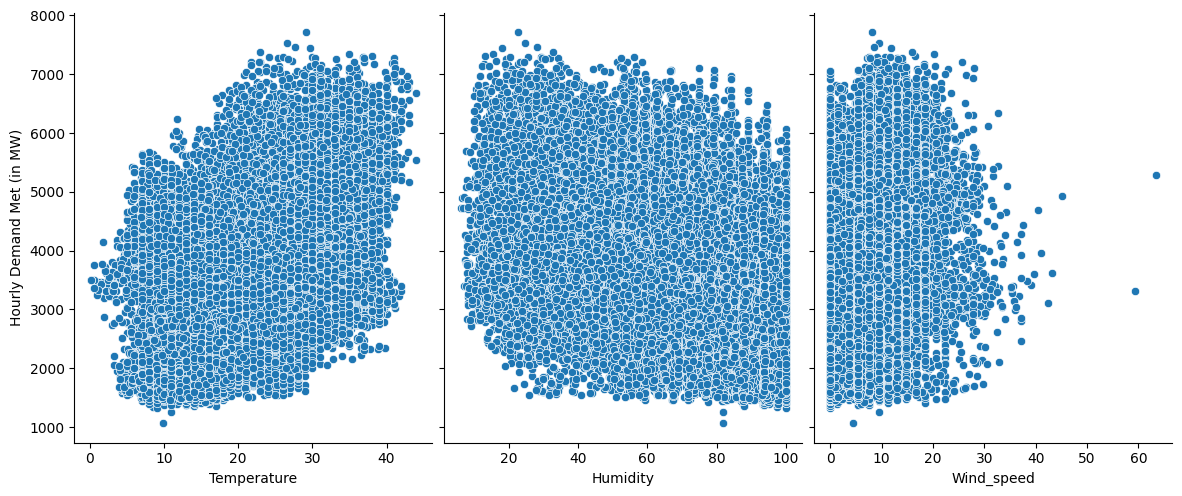

In [10]:
season_mapping = {
    'Light Winter': 0,
    'Heavy Winter': 1,
    'Light Summer': 2,
    'Heavy Summer': 3,
    'Light Rainy':4,
    'Rainy': 5,
    'Autumn': 6
}

df['Season'] = df['Season'].map(season_mapping)
# Pairplot for visualizing relationships
sns.pairplot(df, x_vars=['Temperature', 'Humidity', 'Wind_speed'], y_vars='Hourly Demand Met (in MW)', height=5, aspect=0.8)
plt.show()

In [11]:
df.tail()

,Date,Time,Hourly Demand Met (in MW),Season,Weekday,Temperature,Humidity,Wind_speed,Conditions,is_Holiday
29179,2024-04-30,19:00:00,3937.19,3,5,32.0,31.48,13.0,Partially cloudy,0
29180,2024-04-30,20:00:00,3753.42,3,5,31.0,33.32,9.4,Partially cloudy,0
29181,2024-04-30,21:00:00,3543.18,3,5,30.3,39.56,7.0,Partially cloudy,0
29182,2024-04-30,22:00:00,3505.90,3,5,30.0,35.29,11.2,Partially cloudy,0
29183,2024-04-30,23:00:00,3381.62,3,5,29.0,37.38,9.4,Partially cloudy,0


In [12]:
df["Conditions"].unique()

array(['Partially cloudy', 'Clear', 'Overcast', 'Rain, Partially cloudy',
       'Rain, Overcast', 'Rain'], dtype=object)

In [13]:
df["Conditions"]=df["Conditions"].replace({"Partially cloudy":1,"Clear":2,"Overcast":3,"Rain, Partially cloudy":4,"Rain, Overcast":5,"Rain":6})

C:\Users\hp\AppData\Local\Temp\ipykernel_4344\3445878541.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Conditions"]=df["Conditions"].replace({"Partially cloudy":1,"Clear":2,"Overcast":3,"Rain, Partially cloudy":4,"Rain, Overcast":5,"Rain":6})


In [14]:
df.tail()

,Date,Time,Hourly Demand Met (in MW),Season,Weekday,Temperature,Humidity,Wind_speed,Conditions,is_Holiday
29179,2024-04-30,19:00:00,3937.19,3,5,32.0,31.48,13.0,1,0
29180,2024-04-30,20:00:00,3753.42,3,5,31.0,33.32,9.4,1,0
29181,2024-04-30,21:00:00,3543.18,3,5,30.3,39.56,7.0,1,0
29182,2024-04-30,22:00:00,3505.90,3,5,30.0,35.29,11.2,1,0
29183,2024-04-30,23:00:00,3381.62,3,5,29.0,37.38,9.4,1,0


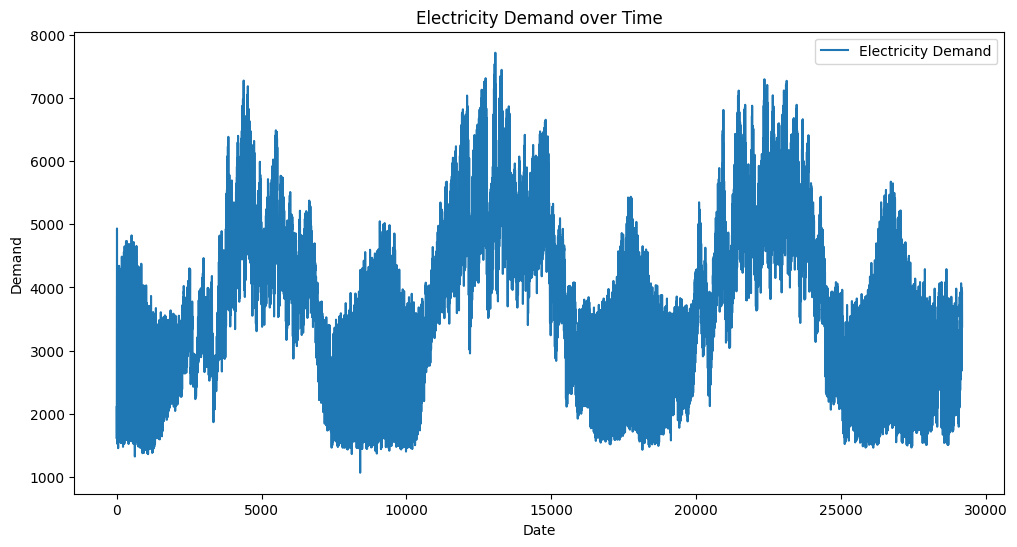

In [15]:
plt.figure(figsize=(12,6))
plt.plot(df['Hourly Demand Met (in MW)'], label='Electricity Demand')
plt.title('Electricity Demand over Time')
plt.xlabel('Date')
plt.ylabel('Demand')
plt.legend()
plt.show()


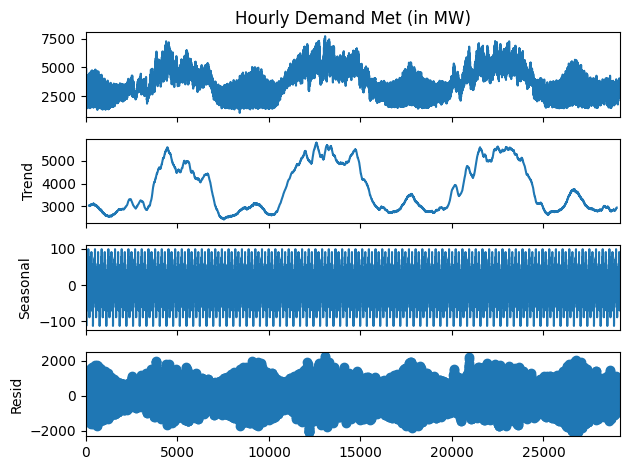

In [16]:
# Decompose the time series
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition = seasonal_decompose(df['Hourly Demand Met (in MW)'], model='additive', period=365)
decomposition.plot()
plt.show()

In [17]:
# Perform stationarity test (ADF test)
from statsmodels.tsa.stattools import adfuller
result = adfuller(df['Hourly Demand Met (in MW)'])
if result[1] <= 0.05 :
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
else:
    print('Grester than 0.05')

ADF Statistic: -4.778041711616743
p-value: 5.9897668354908994e-05


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29184 entries, 0 to 29183
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       29184 non-null  datetime64[ns]
 1   Time                       29184 non-null  object        
 2   Hourly Demand Met (in MW)  29184 non-null  float64       
 3   Season                     29184 non-null  int64         
 4   Weekday                    29184 non-null  int32         
 5   Temperature                29184 non-null  float64       
 6   Humidity                   29184 non-null  float64       
 7   Wind_speed                 29184 non-null  float64       
 8   Conditions                 29184 non-null  int64         
 9   is_Holiday                 29184 non-null  int64         
dtypes: datetime64[ns](1), float64(4), int32(1), int64(3), object(1)
memory usage: 2.1+ MB


# SARIMAX model

In [19]:
df.head()

,Date,Time,Hourly Demand Met (in MW),Season,Weekday,Temperature,Humidity,Wind_speed,Conditions,is_Holiday
0,2021-01-01,00:00:00,2105.45,1,0,4.5,98.02,0.0,1,0
1,2021-01-01,01:00:00,1821.40,1,0,8.0,93.40,0.0,1,0
2,2021-01-01,02:00:00,1673.98,1,0,5.8,97.70,0.0,1,0
3,2021-01-01,03:00:00,1607.68,1,0,4.3,97.48,0.0,2,0
4,2021-01-01,04:00:00,1662.72,1,0,6.0,100.00,0.0,2,0


In [20]:
import numpy as np
from pmdarima import auto_arima

import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.preprocessing import MinMaxScaler
# Assuming df is your original DataFrame with the Demand column
# Select relevant features, normalizing only specific columns
exog_vars = df[['Humidity', 'Temperature', 'Wind_speed','Season']]

# Initialize the StandardScaler
scaler = MinMaxScaler()

# Normalize only the 'Humidity', 'Temperature', and 'Wind Speed' columns
exog_vars[['Humidity', 'Temperature', 'Wind_speed','Season']] = scaler.fit_transform(exog_vars[['Humidity', 'Temperature', 'Wind_speed','Season']])
'''
model = auto_arima(df['Demand'], seasonal=True, m=12,
                   exogenous=exog_vars,
                   stepwise=True, trace=True)
'''
train_data = df['Hourly Demand Met (in MW)'][:-365]   # Exclude last 365 rows for training
test_data = df['Hourly Demand Met (in MW)'][-365:]    # Last 365 rows for testing

# Split the exogenous variables as well, if you have them
train_exog = exog_vars[:-365]
test_exog = exog_vars[-365:]


# Fit the SARIMAX model with the updated exogenous variables
model = SARIMAX(df['Hourly Demand Met (in MW)'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), exog=exog_vars)
model_fit = model.fit()

C:\Users\hp\AppData\Local\Temp\ipykernel_4344\2457643684.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exog_vars[['Humidity', 'Temperature', 'Wind_speed','Season']] = scaler.fit_transform(exog_vars[['Humidity', 'Temperature', 'Wind_speed','Season']])
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [21]:
len(df)

29184

In [22]:
# Make predictions
df['SARIMAX_Predictions'] = model_fit.predict(start=len(train_data),end=len(train_data) + len(test_data) - 1, exog=test_exog)

# Shift predictions to align with actual values
df['SARIMAX_Predictions'] = df['SARIMAX_Predictions'].shift(-1)

# Drop NaN values after shifting
df = df.dropna()

# Evaluate the model
predictions = df['SARIMAX_Predictions']
actual = df['Hourly Demand Met (in MW)']

# Calculate and print evaluation metrics
mae = mean_absolute_error(actual, predictions)
mse = mean_squared_error(actual, predictions)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(actual, predictions)
r2 = r2_score(actual, predictions)

print(f'MAE: {mae}, MSE: {mse}, RMSE: {rmse}, MAPE: {mape * 100:.2f}%, R2: {r2}')

MAE: 150.42137932116157, MSE: 36971.80746470738, RMSE: 192.28054364575576, MAPE: 5.48%, R2: 0.905820608238811


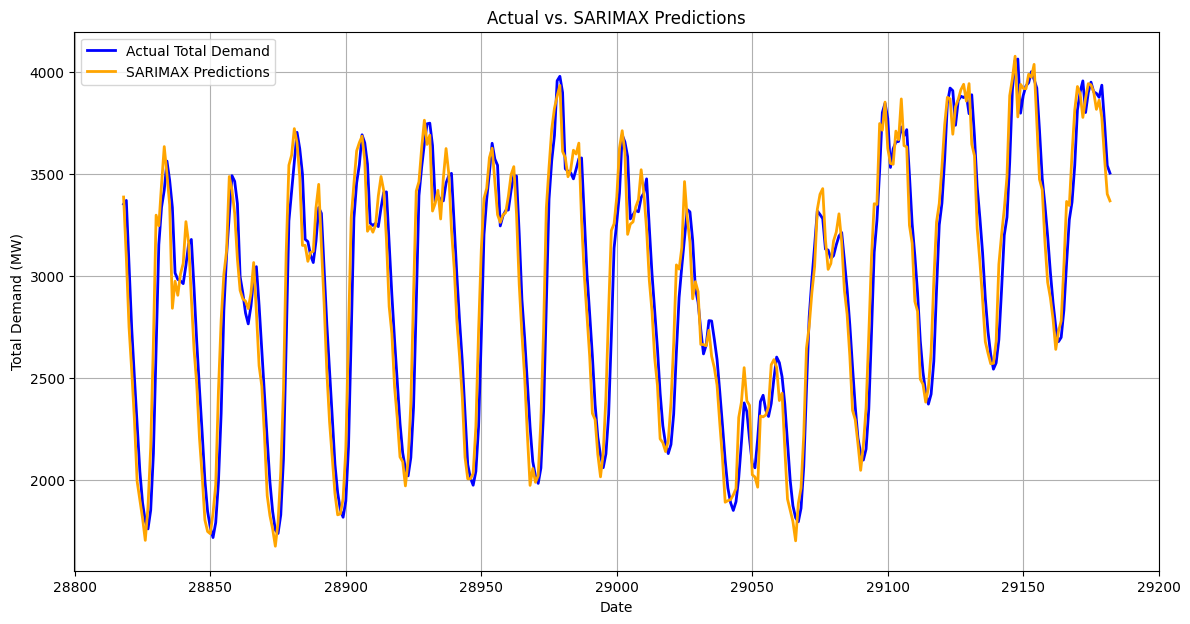

In [23]:
import matplotlib.pyplot as plt

#actual = df['Demand']
#predictions = df['SARIMAX_Predictions']

plt.figure(figsize=(14, 7))
plt.plot(actual.index, actual, label='Actual Total Demand', color='blue', linewidth=2)
plt.plot(predictions.index, predictions, label='SARIMAX Predictions', color='orange', linewidth=2)
plt.title('Actual vs. SARIMAX Predictions')
plt.xlabel('Date')
plt.ylabel('Total Demand (MW)')
plt.legend()
plt.grid()
plt.show()

In [24]:
df["SARIMAX_Predictions"]

28818    3388.642981
28819    3092.915891
28820    2751.554291
28821    2535.224268
28822    2294.393961
            ...     
29178    3863.695839
29179    3778.285424
29180    3578.932523
29181    3403.220582
29182    3369.634212
Name: SARIMAX_Predictions, Length: 365, dtype: float64

In [25]:
print(df)

            Date      Time  Hourly Demand Met (in MW)  Season  Weekday  \
28818 2024-04-15  18:00:00                    3354.05       3        1   
28819 2024-04-15  19:00:00                    3371.90       3        1   
28820 2024-04-15  20:00:00                    3062.60       3        1   
28821 2024-04-15  21:00:00                    2743.10       3        1   
28822 2024-04-15  22:00:00                    2502.75       3        1   
...          ...       ...                        ...     ...      ...   
29178 2024-04-30  18:00:00                    3877.98       3        5   
29179 2024-04-30  19:00:00                    3937.19       3        5   
29180 2024-04-30  20:00:00                    3753.42       3        5   
29181 2024-04-30  21:00:00                    3543.18       3        5   
29182 2024-04-30  22:00:00                    3505.90       3        5   

       Temperature  Humidity  Wind_speed  Conditions  is_Holiday  \
28818         29.0     56.32         5.7   

In [26]:
df.head()

,Date,Time,Hourly Demand Met (in MW),Season,Weekday,Temperature,Humidity,Wind_speed,Conditions,is_Holiday,SARIMAX_Predictions
28818,2024-04-15,18:00:00,3354.05,3,1,29.0,56.32,5.7,3,0,3388.642981
28819,2024-04-15,19:00:00,3371.90,3,1,29.0,42.56,7.6,1,0,3092.915891
28820,2024-04-15,20:00:00,3062.60,3,1,28.0,51.24,7.6,1,0,2751.554291
28821,2024-04-15,21:00:00,2743.10,3,1,26.2,69.05,1.5,1,0,2535.224268
28822,2024-04-15,22:00:00,2502.75,3,1,26.0,61.39,3.6,1,0,2294.393961


In [27]:
# Assuming 'actual' and 'predictions' are defined and have the same length as the sliced dates
df.iloc[:, 0] = pd.to_datetime(df.iloc[:, 0], errors='coerce')  # Convert to datetime

results_df = pd.DataFrame({
    'Date': df["Date"],
    "Time": df["Time"],
    'Actual': actual,
    'Predicted': predictions
})

In [28]:
results_df[:365]

,Date,Time,Actual,Predicted
28818,2024-04-15,18:00:00,3354.05,3388.642981
28819,2024-04-15,19:00:00,3371.90,3092.915891
28820,2024-04-15,20:00:00,3062.60,2751.554291
28821,2024-04-15,21:00:00,2743.10,2535.224268
28822,2024-04-15,22:00:00,2502.75,2294.393961
...,...,...,...,...
29178,2024-04-30,18:00:00,3877.98,3863.695839
29179,2024-04-30,19:00:00,3937.19,3778.285424
29180,2024-04-30,20:00:00,3753.42,3578.932523
29181,2024-04-30,21:00:00,3543.18,3403.220582


In [29]:
df2 = pd.DataFrame(results_df[['Actual','Predicted']])
df2['diff'] = df2['Actual'] - df2['Predicted']
df2

,Actual,Predicted,diff
28818,3354.05,3388.642981,-34.592981
28819,3371.90,3092.915891,278.984109
28820,3062.60,2751.554291,311.045709
28821,2743.10,2535.224268,207.875732
28822,2502.75,2294.393961,208.356039
...,...,...,...
29178,3877.98,3863.695839,14.284161
29179,3937.19,3778.285424,158.904576
29180,3753.42,3578.932523,174.487477
29181,3543.18,3403.220582,139.959418


In [30]:
df2.to_csv("Final Sarimax Output.csv")

In [31]:
import pickle
with open('model/sarimax_model.pkl', 'wb') as f:
    pickle.dump(model_fit, f)


In [32]:
import joblib
joblib.dump(model, 'model/sarimax_model.joblib')

['model/sarimax_model.joblib']

In [36]:
import pandas as pd
import numpy as np
import requests
import pickle
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

# Your API Key
api_key = "DUS2HREYY2L7ZVCLY7SKDXYDZ"

# Base URL for the Visual Crossing Weather API
base_url = "https://weather.visualcrossing.com/VisualCrossingWebServices/rest/services/timeline"


In [37]:
# Function to fetch hourly weather data for a given location and date
def fetch_hourly_weather_data(location, date):
    params = {
        "unitGroup": "metric",  # For temperature in Celsius
        "key": api_key,
        "contentType": "json"
    }

    url = f"{base_url}/{location}/{date}"
    response = requests.get(url, params=params)

    if response.status_code == 200:
        data = response.json()
        try:
            if "days" in data:
                day_data = data["days"][0]
                hourly_data = day_data.get("hours", [])

                hours, temperatures, humidities, windspeeds, conditions = [], [], [], [], []
                for hour in hourly_data:
                    hours.append(hour["datetime"])
                    temperatures.append(hour["temp"])
                    humidities.append(hour["humidity"])
                    windspeeds.append(hour["windspeed"])
                    conditions.append(hour["conditions"])

                weather_array = np.array([hours, temperatures, humidities, windspeeds, conditions]).T
                return weather_array
            else:
                print("Error: 'days' field is missing in the API response.")
                return None
        except KeyError as e:
            print(f"KeyError: {e} - Check if the response structure has changed.")
            return None
    else:
        print(f"Failed to fetch data. HTTP Status code: {response.status_code}")
        return None


In [38]:
# Function to prepare data for SARIMAX model
def prepare_sarimax_data(df):
    # Ensure the dataset has a 'Date' column; if not, create one
    if 'Date' not in df.columns:
        df['Date'] = pd.to_datetime(df.index)  # Assuming the index is in datetime format
        print("Note: 'Date' column created from index.")

    # Handle missing 'Weekday' column and create it if necessary
    if 'Weekday' not in df.columns:
        df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
        df['Weekday'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

    # Handle missing 'Season' column and create it if necessary
    if 'Season' not in df.columns:
        # Default season assignment based on temperature or any other feature (you can modify this logic as needed)
        print("Season column is missing. Adding default seasons based on temperature.")
        
        # Convert 'Temperature' column to numeric (in case it contains strings)
        df['Temperature'] = pd.to_numeric(df['Temperature'], errors='coerce')

        # Assign seasons based on temperature ranges
        df['Season'] = np.where(df['Temperature'] <= 15, 'Light Winter', 
                                np.where(df['Temperature'] <= 30, 'Light Summer', 'Heavy Summer'))
        print("Seasons assigned based on Temperature.")

    # Map Season to numerical values (if you want to keep this as a numerical feature)
    season_mapping = {
        'Light Winter': 0, 'Heavy Winter': 1, 'Light Summer': 2, 'Heavy Summer': 3,
        'Light Rainy': 4, 'Rainy': 5, 'Autumn': 6
    }
    df['Season'] = df['Season'].map(season_mapping).fillna(-1)  # Filling NaN with -1 if any

    # Scale weather-related features
    scaler = MinMaxScaler()
    df[['Humidity', 'Temperature', 'Wind_speed', 'Season']] = scaler.fit_transform(
        df[['Humidity', 'Temperature', 'Wind_speed', 'Season']]
    )
    
    return df

In [39]:
# Function to load the saved SARIMAX model (using pickle or joblib)
def load_saved_model(model_path):
    with open(model_path, 'rb') as f:
        model = pickle.load(f)
    return model

# Function to load the saved SARIMAX model (using joblib)
def load_saved_model_joblib(model_path):
    model = joblib.load(model_path)
    return model

def predict_using_loaded_model(df, model_path, exog_vars):
    """
    Predict electricity demand using a pre-trained SARIMAX model.

    Parameters:
    - df: DataFrame containing the historical data.
    - model_path: Path to the saved SARIMAX model.
    - exog_vars: DataFrame containing the exogenous variables.

    Returns:
    - None
    """
    # Load the saved model (can use either pickle or joblib)
    model_fit = load_saved_model(model_path)  # Or use load_saved_model_joblib()

    # Split the data into test sets
    test_data = df['Hourly Demand Met (in MW)'][-365:]
    test_exog = exog_vars[-365:]

    # Ensure test_exog has the same length as test_data
    if len(test_exog) != len(test_data):
        raise ValueError("Mismatch between test data and exogenous variables length.")

    # Make predictions
    try:
        predictions = model_fit.predict(
            start=test_data.index[0],  # Use the first index of the test data
            end=test_data.index[-1],  # Use the last index of the test data
            exog=test_exog
        )
    except Exception as e:
        print(f"Error during prediction: {e}")
        return

    # Evaluate the model
    mae = mean_absolute_error(test_data, predictions)
    mse = mean_squared_error(test_data, predictions)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(test_data, predictions)
    r2 = r2_score(test_data, predictions)

    print(f"MAE: {mae}, MSE: {mse}, RMSE: {rmse}, MAPE: {mape * 100:.2f}%, R2: {r2}")

    # Plot the actual vs predicted values
    plt.figure(figsize=(12, 7))
    plt.plot(test_data.index, test_data, label='Actual Demand', color='blue', linewidth=2)
    plt.plot(predictions.index, predictions, label='SARIMAX Predictions', color='orange', linewidth=2)
    plt.title('Actual vs. SARIMAX Predictions')
    plt.xlabel('Date')
    plt.ylabel('Total Demand (MW)')
    plt.legend()
    plt.grid()
    plt.show()



In [40]:
def predict_future_demand(location, future_date, model_path):
    weather_array = fetch_hourly_weather_data(location, future_date)

    if weather_array is not None:
        # Process the weather data
        future_weather_df = pd.DataFrame(weather_array, columns=["Hour", "Temperature", "Humidity", "Wind_speed", "Conditions"])

        # Preprocess the future weather data
        future_weather_df = prepare_sarimax_data(future_weather_df)

        # Use the loaded SARIMAX model to predict future demand
        future_exog = future_weather_df[['Temperature', 'Humidity', 'Wind_speed', 'Season']]  # Add more exogenous variables if necessary
        model_fit = load_saved_model(model_path)
        future_predictions = model_fit.predict(start=len(future_weather_df), end=len(future_weather_df) + 23, exog=future_exog)

        # Generate the datetime for each prediction hour
        date_time_index = pd.date_range(start=f'{future_date} 00:00:00', periods=24, freq='H')

        # Combine the predictions with the date and time
        prediction_results = pd.DataFrame({
            'DateTime': date_time_index,
            'Predicted Demand (MW)': future_predictions
        })

        # Convert 'DateTime' to string format for cleaner output
        prediction_results['DateTime'] = prediction_results['DateTime'].dt.strftime('%Y-%m-%d %H:%M:%S')

        # Display predictions without Timestamp
        print(f"Predicted Future Demand for {location} on {future_date}:")
        print(prediction_results)
        
        # Plot the predictions
        plt.figure(figsize=(12, 6))
        plt.plot(prediction_results['DateTime'], prediction_results['Predicted Demand (MW)'], marker='o', color='b', label='Predicted Demand (MW)')
        plt.title(f'Predicted Electricity Demand for {location} on {future_date} (24-Hour)')
        plt.xlabel('Time')
        plt.ylabel('Predicted Demand (MW)')

        # Explicitly set x-ticks for all 24 hours
        plt.xticks(prediction_results['DateTime'], prediction_results['DateTime'], rotation=45)
        
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()


MAE: 53.13045101508728, MSE: 5649.265247603463, RMSE: 75.1615942327161, MAPE: 1.86%, R2: 0.9856117522934404


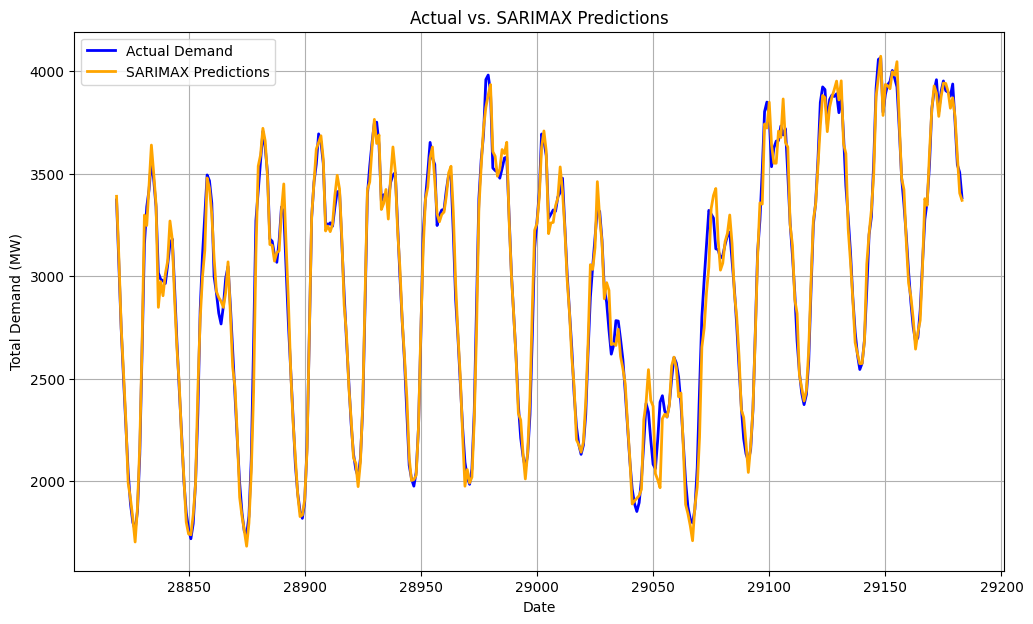

Note: 'Date' column created from index.
Season column is missing. Adding default seasons based on temperature.
Seasons assigned based on Temperature.


C:\Users\hp\AppData\Local\Temp\ipykernel_4344\2199480811.py:17: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  date_time_index = pd.date_range(start=f'{future_date} 00:00:00', periods=24, freq='H')


Predicted Future Demand for dehli on 2024-12-24:
               DateTime  Predicted Demand (MW)
24  2024-12-24 00:00:00            2344.747267
25  2024-12-24 01:00:00            1496.264824
26  2024-12-24 02:00:00            1558.001133
27  2024-12-24 03:00:00            1636.421950
28  2024-12-24 04:00:00            1485.209651
29  2024-12-24 05:00:00            1915.220190
30  2024-12-24 06:00:00            2477.581789
31  2024-12-24 07:00:00            3125.371444
32  2024-12-24 08:00:00            3749.513144
33  2024-12-24 09:00:00            3875.359758
34  2024-12-24 10:00:00            4074.346792
35  2024-12-24 11:00:00            4156.383173
36  2024-12-24 12:00:00            3928.133957
37  2024-12-24 13:00:00            3291.808269
38  2024-12-24 14:00:00            3112.412850
39  2024-12-24 15:00:00            3177.730347
40  2024-12-24 16:00:00            3099.019449
41  2024-12-24 17:00:00            3249.769411
42  2024-12-24 18:00:00            3706.401024
43  2024-12

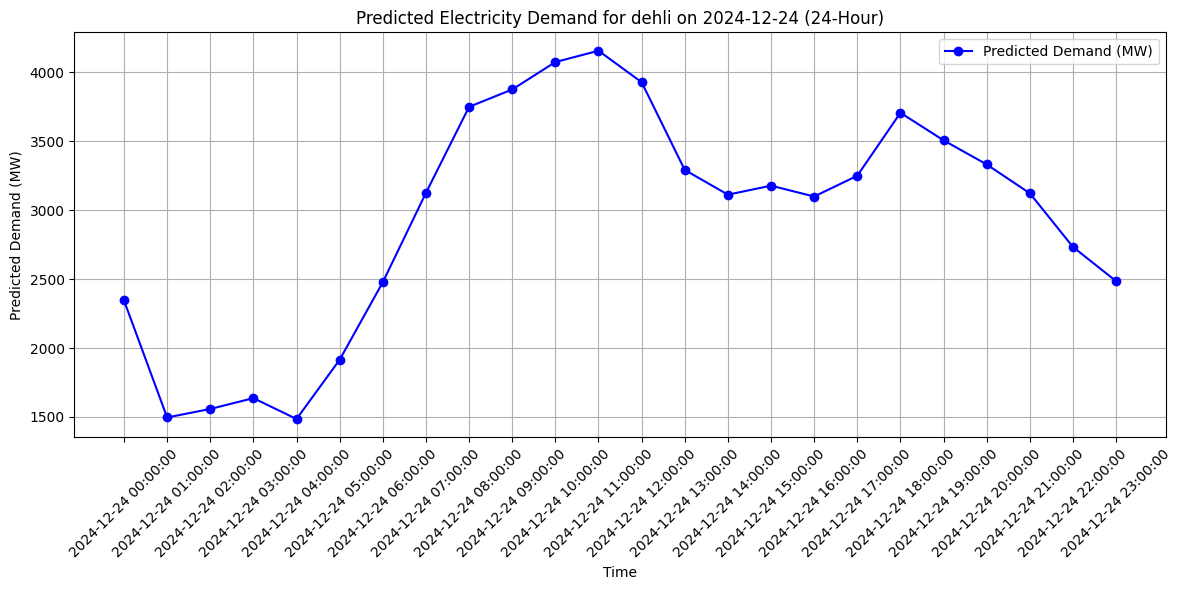

In [ ]:
# User input for location, date, and model path
location = input("Enter the location (e.g., New York): ")
date = input("Enter the date for future prediction (YYYY-MM-DD): ")
model_path = "D:\last main\model\sarimax_model.pkl"  # Path to the saved model (pickle format)

# Load and prepare your data
df = pd.read_excel("D:\last main\data\Training_Data.xlsx")  # Update with correct file path
df = prepare_sarimax_data(df)

# Prepare exogenous variables from weather data
exog_vars = df[['Humidity', 'Temperature', 'Wind_speed', 'Season']]  # Add any additional variables as needed

# Use the pre-trained model to predict demand
predict_using_loaded_model(df, model_path, exog_vars)

# Predict future demand based on weather forecast
predict_future_demand(location, date, model_path)
